# RAM Antivirus — Complete End-to-End Master EDA & Data Pipeline
### **Comprehensive Analysis of All 43 Features in NSL-KDD Dataset**
**Objective:** Load raw data, inspect all 43 columns, check data types and statistics, audit null values one-by-one, perform categorical encoding, feature selection, and data scaling in simple, step-by-step flow.

---


In [1]:
# Optional: Run this if any package is missing in your current kernel
# %pip install -q joblib scikit-learn seaborn matplotlib pandas numpy pyod

import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.ensemble import RandomForestClassifier

# Configure visual style
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

print("[OK] Setup completed successfully!")


[OK] Setup completed successfully!


---
## Step 1: Define All 43 Available Columns
The raw dataset contains 41 operational and host attributes + 1 attack label + 1 difficulty score.


In [2]:
# All 43 columns present in the raw NSL-KDD dataset
ALL_43_COLUMNS = [
    "duration", "protocol_type", "service", "flag", "src_bytes", "dst_bytes",
    "land", "wrong_fragment", "urgent", "hot", "num_failed_logins", "logged_in",
    "num_compromised", "root_shell", "su_attempted", "num_root", "num_file_creations",
    "num_shells", "num_access_files", "num_outbound_cmds", "is_host_login",
    "is_guest_login", "count", "srv_count", "serror_rate", "srv_serror_rate",
    "rerror_rate", "srv_rerror_rate", "same_srv_rate", "diff_srv_rate",
    "srv_diff_host_rate", "dst_host_count", "dst_host_srv_count",
    "dst_host_same_srv_rate", "dst_host_diff_srv_rate", "dst_host_same_src_port_rate",
    "dst_host_srv_diff_host_rate", "dst_host_serror_rate", "dst_host_srv_serror_rate",
    "dst_host_rerror_rate", "dst_host_srv_rerror_rate", "label", "difficulty"
]

print(f"Total columns defined: {len(ALL_43_COLUMNS)}")


Total columns defined: 43


---
## Step 2: Load Raw Dataset & Inspect First / Last Rows


In [3]:
DATA_DIR = os.path.join("..", "backend", "data")

train_file = os.path.join(DATA_DIR, "KDDTrain+.txt")
test_file = os.path.join(DATA_DIR, "KDDTest+.txt")

df = pd.read_csv(train_file, header=None, names=ALL_43_COLUMNS)
df_test = pd.read_csv(test_file, header=None, names=ALL_43_COLUMNS)

print(f"Dataset successfully loaded!")
print(f"Train Shape: {df.shape[0]:,} Rows × {df.shape[1]} Columns")
print(f"Test Shape:  {df_test.shape[0]:,} Rows × {df_test.shape[1]} Columns")


Dataset successfully loaded!
Train Shape: 125,973 Rows × 43 Columns
Test Shape:  22,544 Rows × 43 Columns


In [4]:
# Display first 5 rows (df.head())
df.head()


,duration,protocol_type,service,flag,src_bytes,dst_bytes,land,wrong_fragment,urgent,hot,...,dst_host_same_srv_rate,dst_host_diff_srv_rate,dst_host_same_src_port_rate,dst_host_srv_diff_host_rate,dst_host_serror_rate,dst_host_srv_serror_rate,dst_host_rerror_rate,dst_host_srv_rerror_rate,label,difficulty
0,0,tcp,ftp_data,SF,491,0,0,0,0,0,...,0.17,0.03,0.17,0.00,0.00,0.00,0.05,0.00,normal,20
1,0,udp,other,SF,146,0,0,0,0,0,...,0.00,0.60,0.88,0.00,0.00,0.00,0.00,0.00,normal,15
2,0,tcp,private,S0,0,0,0,0,0,0,...,0.10,0.05,0.00,0.00,1.00,1.00,0.00,0.00,neptune,19
3,0,tcp,http,SF,232,8153,0,0,0,0,...,1.00,0.00,0.03,0.04,0.03,0.01,0.00,0.01,normal,21
4,0,tcp,http,SF,199,420,0,0,0,0,...,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,normal,21


In [5]:
# Display last 5 rows (df.tail())
df.tail()


,duration,protocol_type,service,flag,src_bytes,dst_bytes,land,wrong_fragment,urgent,hot,...,dst_host_same_srv_rate,dst_host_diff_srv_rate,dst_host_same_src_port_rate,dst_host_srv_diff_host_rate,dst_host_serror_rate,dst_host_srv_serror_rate,dst_host_rerror_rate,dst_host_srv_rerror_rate,label,difficulty
125968,0,tcp,private,S0,0,0,0,0,0,0,...,0.10,0.06,0.00,0.0,1.00,1.0,0.00,0.0,neptune,20
125969,8,udp,private,SF,105,145,0,0,0,0,...,0.96,0.01,0.01,0.0,0.00,0.0,0.00,0.0,normal,21
125970,0,tcp,smtp,SF,2231,384,0,0,0,0,...,0.12,0.06,0.00,0.0,0.72,0.0,0.01,0.0,normal,18
125971,0,tcp,klogin,S0,0,0,0,0,0,0,...,0.03,0.05,0.00,0.0,1.00,1.0,0.00,0.0,neptune,20
125972,0,tcp,ftp_data,SF,151,0,0,0,0,0,...,0.30,0.03,0.30,0.0,0.00,0.0,0.00,0.0,normal,21


---
## Step 3: Check Data Types & Schema (`df.info()`)


In [6]:
# Full schema and memory info
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 125973 entries, 0 to 125972
Data columns (total 43 columns):
 #   Column                       Non-Null Count   Dtype  
---  ------                       --------------   -----  
 0   duration                     125973 non-null  int64  
 1   protocol_type                125973 non-null  object 
 2   service                      125973 non-null  object 
 3   flag                         125973 non-null  object 
 4   src_bytes                    125973 non-null  int64  
 5   dst_bytes                    125973 non-null  int64  
 6   land                         125973 non-null  int64  
 7   wrong_fragment               125973 non-null  int64  
 8   urgent                       125973 non-null  int64  
 9   hot                          125973 non-null  int64  
 10  num_failed_logins            125973 non-null  int64  
 11  logged_in                    125973 non-null  int64  
 12  num_compromised              125973 non-null  int64  
 13 

In [7]:
# Count of data types
df.dtypes.value_counts()


int64      24
float64    15
object      4
Name: count, dtype: int64

---
## Step 4: Check for Null / Missing Values (All 43 Columns One by One)
We inspect every single column individually to verify data completeness.


In [8]:
# Check null values for all 43 columns one by one
null_series = df.isnull().sum()
null_df = pd.DataFrame({
    "Column Name": null_series.index,
    "Missing Values": null_series.values,
    "Missing Percentage (%)": (null_series.values / len(df)) * 100
})

print(f"Total missing values in entire dataset: {null_series.sum()}")
null_df


Total missing values in entire dataset: 0


,Column Name,Missing Values,Missing Percentage (%)
0,duration,0,0.0
1,protocol_type,0,0.0
2,service,0,0.0
3,flag,0,0.0
4,src_bytes,0,0.0
5,dst_bytes,0,0.0
6,land,0,0.0
7,wrong_fragment,0,0.0
8,urgent,0,0.0
9,hot,0,0.0


In [9]:
# Check for duplicate rows
duplicate_count = df.duplicated().sum()
print(f"Duplicate rows count: {duplicate_count}")


Duplicate rows count: 0


---
## Step 5: Statistical Summary of Numerical Columns (`df.describe()`)
Computes mean, standard deviation, minimum, quartiles, and maximum for all numerical attributes.


In [10]:
# Statistical summary of numerical columns
df.describe().T


,count,mean,std,min,25%,50%,75%,max
duration,125973.0,287.144650,2.604515e+03,0.0,0.00,0.00,0.00,4.290800e+04
src_bytes,125973.0,45566.743000,5.870331e+06,0.0,0.00,44.00,276.00,1.379964e+09
dst_bytes,125973.0,19779.114421,4.021269e+06,0.0,0.00,0.00,516.00,1.309937e+09
land,125973.0,0.000198,1.408607e-02,0.0,0.00,0.00,0.00,1.000000e+00
wrong_fragment,125973.0,0.022687,2.535300e-01,0.0,0.00,0.00,0.00,3.000000e+00
urgent,125973.0,0.000111,1.436603e-02,0.0,0.00,0.00,0.00,3.000000e+00
hot,125973.0,0.204409,2.149968e+00,0.0,0.00,0.00,0.00,7.700000e+01
num_failed_logins,125973.0,0.001222,4.523914e-02,0.0,0.00,0.00,0.00,5.000000e+00
logged_in,125973.0,0.395736,4.890101e-01,0.0,0.00,0.00,1.00,1.000000e+00
num_compromised,125973.0,0.279250,2.394204e+01,0.0,0.00,0.00,0.00,7.479000e+03


---
## Step 6: Categorical Feature Analysis (`protocol_type`, `service`, `flag`)


In [11]:
print("=== Protocol Distribution ===")
print(df["protocol_type"].value_counts())

print("\n=== Top 10 Services ===")
print(df["service"].value_counts().head(10))

print("\n=== Top 5 Connection Flags ===")
print(df["flag"].value_counts().head(5))


=== Protocol Distribution ===
protocol_type
tcp     102689
udp      14993
icmp      8291
Name: count, dtype: int64

=== Top 10 Services ===
service
http        40338
private     21853
domain_u     9043
smtp         7313
ftp_data     6860
eco_i        4586
other        4359
ecr_i        3077
telnet       2353
finger       1767
Name: count, dtype: int64

=== Top 5 Connection Flags ===
flag
SF      74945
S0      34851
REJ     11233
RSTR     2421
RSTO     1562
Name: count, dtype: int64


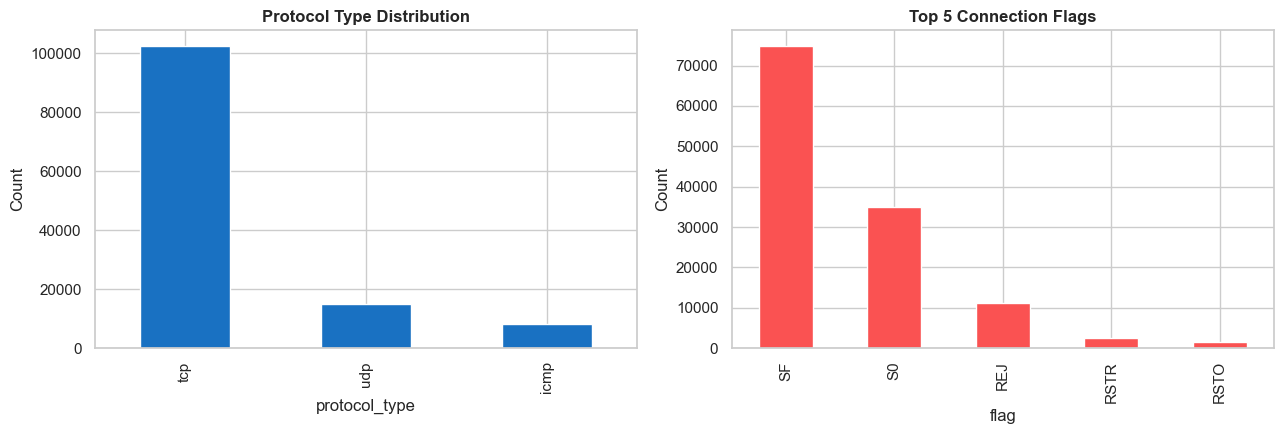

In [12]:
# Plotting Categorical Features
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))

df["protocol_type"].value_counts().plot(kind="bar", ax=ax1, color="#1971c2")
ax1.set_title("Protocol Type Distribution", fontweight="bold")
ax1.set_ylabel("Count")

df["flag"].value_counts().head(5).plot(kind="bar", ax=ax2, color="#fa5252")
ax2.set_title("Top 5 Connection Flags", fontweight="bold")
ax2.set_ylabel("Count")

plt.tight_layout()
plt.show()


---
## Step 7: Encoding & Target Binarization
1. **Binary Encoding:** We create `is_attack`: $0 = \text{Normal}$, $1 = \text{Attack}$.
2. **Label Encoding:** We convert text columns (`protocol_type`, `service`, `flag`) to numeric values.
3. **Attack Taxonomy:** We map 39 attack types into 4 standard categories (DoS, Probe, R2L, U2R).


In [13]:
# Target Binarization
df["clean_label"] = df["label"].str.strip().str.lower()
df["is_attack"] = (df["clean_label"] != "normal").astype(int)

# Mapping attack types to families
ATTACK_CATEGORIES = {
    "normal": "Normal",
    "neptune": "DoS", "back": "DoS", "land": "DoS", "pod": "DoS", "smurf": "DoS",
    "teardrop": "DoS", "mailbomb": "DoS", "processtable": "DoS", "udpstorm": "DoS", "apache2": "DoS", "worm": "DoS",
    "ipsweep": "Probe", "nmap": "Probe", "portsweep": "Probe", "satan": "Probe", "mscan": "Probe", "saint": "Probe",
    "ftp_write": "R2L", "guess_passwd": "R2L", "imap": "R2L", "multihop": "R2L", "phf": "R2L", "spy": "R2L",
    "warezclient": "R2L", "warezmaster": "R2L", "sendmail": "R2L", "named": "R2L", "snmpgetattack": "R2L",
    "snmpguess": "R2L", "xlock": "R2L", "xsnoop": "R2L", "httptunnel": "R2L",
    "buffer_overflow": "U2R", "loadmodule": "U2R", "perl": "U2R", "rootkit": "U2R", "ps": "U2R", "xterm": "U2R", "sqlexec": "U2R"
}

df["attack_family"] = df["clean_label"].map(lambda x: ATTACK_CATEGORIES.get(x, "Unknown"))

print("=== Binary Target Counts ===")
print(df["is_attack"].value_counts())
print(f"\nContamination Rate (Attack %): {df['is_attack'].mean()*100:.2f}%")

print("\n=== Attack Family Breakdown ===")
print(df["attack_family"].value_counts())


=== Binary Target Counts ===
is_attack
0    67343
1    58630
Name: count, dtype: int64

Contamination Rate (Attack %): 46.54%

=== Attack Family Breakdown ===
attack_family
Normal    67343
DoS       45927
Probe     11656
R2L         995
U2R          52
Name: count, dtype: int64


In [14]:
# Encoding Categorical Features using LabelEncoder
encoded_df = df.copy()
le_dict = {}

for col in ["protocol_type", "service", "flag"]:
    le = LabelEncoder()
    encoded_df[col] = le.fit_transform(encoded_df[col])
    le_dict[col] = le

print("Categorical columns successfully converted to numerical values!")
encoded_df[["protocol_type", "service", "flag"]].head()


Categorical columns successfully converted to numerical values!


,protocol_type,service,flag
0,1,20,9
1,2,44,9
2,1,49,5
3,1,24,9
4,1,24,9


---
## Step 8: Feature Importance & Selection (Random Forest Ranking)
We train a Random Forest on all candidate features to find the most important predictors.  
**Note:** `label` and `difficulty` are excluded to prevent target leakage.


In [15]:
# Prepare features (exclude target and difficulty)
feature_cols = [c for c in ALL_43_COLUMNS if c not in ["label", "difficulty"]]
X_candidates = encoded_df[feature_cols]
y_target = encoded_df["is_attack"]

# Train Random Forest on sample for speed
sample_idx = np.random.RandomState(42).choice(len(encoded_df), size=15000, replace=False)
rf = RandomForestClassifier(n_estimators=50, random_state=42, n_jobs=-1)
rf.fit(X_candidates.iloc[sample_idx], y_target.iloc[sample_idx])

# Rank features
feature_ranking = pd.Series(rf.feature_importances_, index=feature_cols).sort_values(ascending=False)

print("=== Top 15 Most Important Features ===")
print(feature_ranking.head(15).round(4))


=== Top 15 Most Important Features ===
src_bytes                   0.2501
dst_bytes                   0.1061
flag                        0.0593
dst_host_same_srv_rate      0.0535
dst_host_srv_count          0.0490
logged_in                   0.0454
same_srv_rate               0.0428
srv_serror_rate             0.0384
count                       0.0381
diff_srv_rate               0.0372
protocol_type               0.0370
serror_rate                 0.0341
service                     0.0213
dst_host_serror_rate        0.0213
dst_host_srv_serror_rate    0.0204
dtype: float64


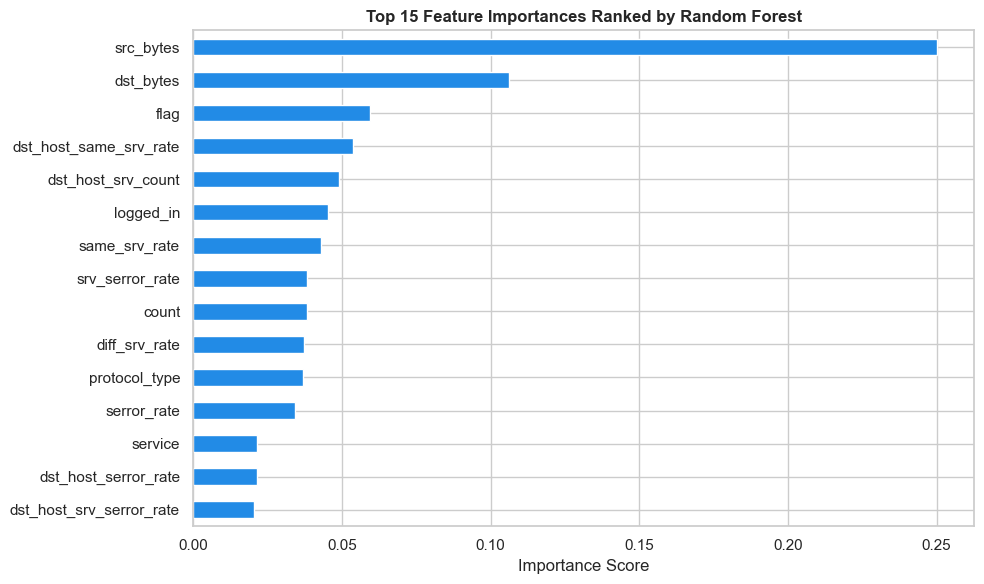

In [16]:
# Plot Feature Importances
plt.figure(figsize=(10, 6))
feature_ranking.head(15).plot(kind="barh", color="#228be6").invert_yaxis()
plt.title("Top 15 Feature Importances Ranked by Random Forest", fontweight="bold")
plt.xlabel("Importance Score")
plt.tight_layout()
plt.show()


---
## Step 9: Correlation Matrix Heatmap
We select the key operational flow features and plot their pairwise correlations.


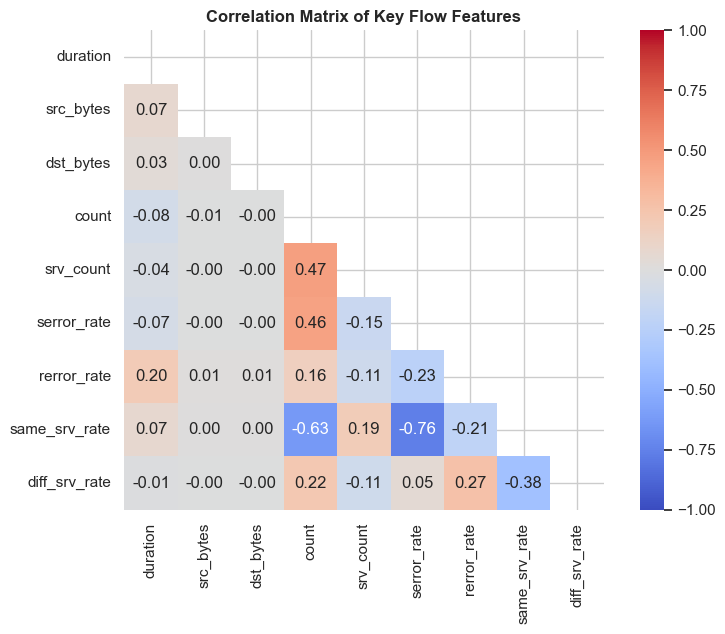

In [17]:
KEY_FLOW_FEATURES = [
    "duration", "src_bytes", "dst_bytes", "count", "srv_count",
    "serror_rate", "rerror_rate", "same_srv_rate", "diff_srv_rate"
]

plt.figure(figsize=(8.5, 6.5))
corr = df[KEY_FLOW_FEATURES].corr()
mask = np.triu(np.ones_like(corr, dtype=bool))

sns.heatmap(corr, mask=mask, cmap="coolwarm", vmin=-1, vmax=1, annot=True, fmt=".2f", square=True)
plt.title("Correlation Matrix of Key Flow Features", fontweight="bold")
plt.tight_layout()
plt.show()


---
## Step 10: Feature Distributions: Normal vs Attack (Boxplots)


C:\Users\lakha\AppData\Local\Temp\ipykernel_18764\3266329669.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=sample_box, x="Class", y="count", ax=axes[0], palette=["#2b8a3e", "#c92a2a"])
C:\Users\lakha\AppData\Local\Temp\ipykernel_18764\3266329669.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=sample_box, x="Class", y="serror_rate", ax=axes[1], palette=["#2b8a3e", "#c92a2a"])
C:\Users\lakha\AppData\Local\Temp\ipykernel_18764\3266329669.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=sample_box, x="Class", y="diff

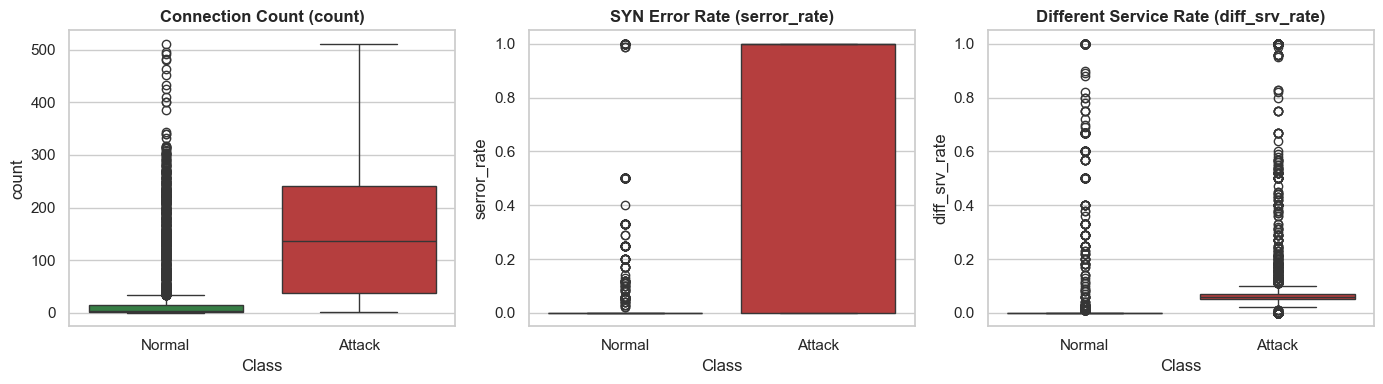

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
sample_box = df.sample(n=10000, random_state=42).copy()
sample_box["Class"] = sample_box["is_attack"].map({0: "Normal", 1: "Attack"})

sns.boxplot(data=sample_box, x="Class", y="count", ax=axes[0], palette=["#2b8a3e", "#c92a2a"])
axes[0].set_title("Connection Count (count)", fontweight="bold")

sns.boxplot(data=sample_box, x="Class", y="serror_rate", ax=axes[1], palette=["#2b8a3e", "#c92a2a"])
axes[1].set_title("SYN Error Rate (serror_rate)", fontweight="bold")

sns.boxplot(data=sample_box, x="Class", y="diff_srv_rate", ax=axes[2], palette=["#2b8a3e", "#c92a2a"])
axes[2].set_title("Different Service Rate (diff_srv_rate)", fontweight="bold")

plt.tight_layout()
plt.show()


---
## Step 11: Data Normalization (`StandardScaler`)
We scale numerical flow features to mean 0 and standard deviation 1.


In [19]:
X_raw = df[KEY_FLOW_FEATURES].fillna(0).values

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_raw)

print(f"Raw shape:    {X_raw.shape}")
print(f"Scaled shape: {X_scaled.shape}")
print(f"Scaled Mean:  {X_scaled.mean(axis=0).round(2)}")
print(f"Scaled Std:   {X_scaled.std(axis=0).round(2)}")
print("\n[OK] General Data Pipeline completed successfully!")


Raw shape:    (125973, 9)
Scaled shape: (125973, 9)
Scaled Mean:  [ 0.  0.  0. -0.  0.  0.  0. -0. -0.]
Scaled Std:   [1. 1. 1. 1. 1. 1. 1. 1. 1.]

[OK] General Data Pipeline completed successfully!
